# Machine Learning Model Training and Ablation Study

This notebook trains SVM (baseline), Random Forest and XGBoost models and measures the contribution of each noise-handling and dependency-handling step.

**Part A** re-evaluates the earlier pipeline (Notebooks 03–05 of the first version) under the full validation protocol.
**Part B** is a cumulative ablation study: each configuration adds one step to the previous one, and all configurations are tested on the **same evaluation windows**.

| Config | Adds |
|---|---|
| C0 | Baseline: raw axes, no filtering, absolute spectra |
| C1 | + Noise handling (spikes, gravity/drift, low-pass, noise-profile subtraction) |
| C2 | + Orientation-invariant channels and relative spectra |
| C3 | + Manoeuvre filtering of training windows |
| C4 | + Speed normalisation (raw speed removed as a feature) |
| C5 | + Per-trip normalisation |
| C6 | + Cross-vehicle stable feature selection (**full pipeline**) |
| C7 | Full pipeline on one dashboard sensor, orientation-invariant channels only (**smartphone deployment model**) |

C0–C6 use both dashboard sensors (the placement that corresponds to a phone in a holder). Other placements are compared in Notebook 07.

**Main metric:** macro-F1 (robust to class imbalance). **Degradation** = Random − LOVO.

In [1]:
# Setup: mount Drive and import the shared Component 4 pipeline (MyDrive/PVS_Code/c4_pipeline.py)
import os, sys, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

CODE_DIR = os.path.join(os.environ.get('C4_DRIVE', '/content/drive/MyDrive'), 'PVS_Code')
assert os.path.exists(os.path.join(CODE_DIR, 'c4_pipeline.py')), \
    'Upload c4_pipeline.py to MyDrive/PVS_Code/ before running this notebook.'
sys.path.insert(0, CODE_DIR)
import c4_pipeline as c4
importlib.reload(c4)
c4.ensure_dirs()
c4.check_setup();

Mounted at /content/drive
Drive folder      : /content/drive/MyDrive
Synced PVS1 found : True
Processed folder  : /content/drive/MyDrive/PVS_Processed True
Feature folder    : /content/drive/MyDrive/PVS_Feature_Datasets_v2 True
Results folder    : /content/drive/MyDrive/PVS_Model_Results_v2 True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
plt.rcParams['figure.dpi'] = 110
CL = c4.CLASSES
COLORS = {'good': 'tab:green', 'regular': 'goldenrod', 'bad': 'tab:red'}

In [3]:
data = c4.load_data()
CONFIGS = c4.ablation_configs()
MODELS = ('SVM', 'RF', 'XGB')

## Part A – Re-evaluation of the earlier pipeline
The earlier feature datasets (`PVS_Feature_Datasets`, 489 features incl. magnetometer and temperature) are evaluated with XGBoost under the random split and all three LOVO folds, with and without magnetometer/temperature features. The scaler is fitted on the training data of each fold (inside the model pipeline).

In [4]:
from sklearn.model_selection import train_test_split
old_rows = []
if os.path.exists(os.path.join(c4.OLD_FEATURE_DIR, 'PVS1_features.csv')):
    old = pd.concat([pd.read_csv(os.path.join(c4.OLD_FEATURE_DIR, f'PVS{n}_features.csv')).assign(pvs=n)
                     for n in range(1, 10)], ignore_index=True)
    old['vehicle'] = old.pvs.map(lambda n: c4.PVS_META[n][0])
    y_old = old['road_condition'].map(c4.CLASS_ID).values
    meta = ['road_condition', 'start_index', 'end_index', 'label_purity', 'pvs', 'vehicle']
    feats_all = [c for c in old.columns if c not in meta]
    feats_clean = [c for c in feats_all if '_mag_' not in c and '_temp_' not in c]
    tr_r, te_r = train_test_split(np.arange(len(old)), test_size=.2, stratify=y_old, random_state=42)
    folds = [('Random', 'random 80/20', tr_r, te_r)] + \
            [('LOVO', f'test={v}', np.where(old.vehicle != v)[0], np.where(old.vehicle == v)[0])
             for v in sorted(old.vehicle.unique())]
    for fs_name, feats in [('earlier features (489)', feats_all), ('without mag/temp', feats_clean)]:
        for split, fold, tr, te in folds:
            m = c4.fit('XGB', old[feats].values[tr], y_old[tr])
            r = c4.metrics(y_old[te], m.predict(old[feats].values[te]))
            old_rows.append({'feature set': fs_name, 'split': split, 'fold': fold, **r})
            print(f'{fs_name:24s} {fold:22s} macro-F1={r["macro_f1"]:.3f}')
    old_res = pd.DataFrame(old_rows)
    old_res.to_csv(os.path.join(c4.RESULTS_DIR, 'earlier_pipeline_reevaluation.csv'), index=False)
    t = old_res.groupby(['feature set', 'split'])['macro_f1'].mean().unstack()
    t['LOVO_std'] = old_res[old_res.split == 'LOVO'].groupby('feature set')['macro_f1'].std()
    t['Degradation'] = t['Random'] - t['LOVO']
    display(t.round(3))
    display(old_res[old_res.split == 'LOVO'].pivot(index='fold', columns='feature set', values='macro_f1').round(3))
else:
    print('Earlier feature datasets not found - Part A skipped.')

earlier features (489)   random 80/20           macro-F1=0.958
earlier features (489)   test=Fiat Bravo        macro-F1=0.803
earlier features (489)   test=Fiat Palio        macro-F1=0.876
earlier features (489)   test=VW Saveiro        macro-F1=0.849
without mag/temp         random 80/20           macro-F1=0.951
without mag/temp         test=Fiat Bravo        macro-F1=0.849
without mag/temp         test=Fiat Palio        macro-F1=0.867
without mag/temp         test=VW Saveiro        macro-F1=0.848


split,LOVO,Random,LOVO_std,Degradation
feature set,,,,
earlier features (489),0.843,0.958,0.037,0.116
without mag/temp,0.855,0.951,0.010,0.096


feature set,earlier features (489),without mag/temp
fold,,
test=Fiat Bravo,0.803,0.849
test=Fiat Palio,0.876,0.867
test=VW Saveiro,0.849,0.848


**How to read Part A:** the earlier result (macro-F1 ≈ 0.87) corresponds to the fold *test = Fiat Palio*. The other two folds show whether that result holds for the other vehicle-drivers, and the random split shows how much performance is lost when the vehicle-driver is unseen.

## Part B – Cumulative ablation study

In [5]:
abl, CMS = [], {}
for name, cfg in CONFIGS.items():
    r, cm = c4.run(data, name, cfg, ['Random', 'LOVO'], MODELS)
    abl.append(r); CMS.update(cm)
abl = pd.concat(abl, ignore_index=True)
abl.to_csv(os.path.join(c4.RESULTS_DIR, 'ablation_results.csv'), index=False)

  C0 Baseline (raw)              Random    random 80/20             SVM=0.930, RF=0.902, XGB=0.943  (35s)
  C0 Baseline (raw)              LOVO      test=Fiat Bravo          SVM=0.738, RF=0.729, XGB=0.818  (29s)
  C0 Baseline (raw)              LOVO      test=Fiat Palio          SVM=0.738, RF=0.879, XGB=0.918  (30s)
  C0 Baseline (raw)              LOVO      test=VW Saveiro          SVM=0.845, RF=0.865, XGB=0.877  (29s)
  C1 + Noise handling            Random    random 80/20             SVM=0.901, RF=0.901, XGB=0.932  (35s)
  C1 + Noise handling            LOVO      test=Fiat Bravo          SVM=0.648, RF=0.705, XGB=0.806  (29s)
  C1 + Noise handling            LOVO      test=Fiat Palio          SVM=0.792, RF=0.872, XGB=0.916  (30s)
  C1 + Noise handling            LOVO      test=VW Saveiro          SVM=0.826, RF=0.855, XGB=0.869  (30s)
  C2 + Invariant repr.           Random    random 80/20             SVM=0.908, RF=0.892, XGB=0.939  (56s)
  C2 + Invariant repr.           LOVO      tes

In [6]:
ABL = c4.degradation_table(abl, order=list(CONFIGS))
display(ABL)
ABL.to_csv(os.path.join(c4.RESULTS_DIR, 'ablation_table.csv'))

best = ABL.xs('C6 + Stable selection (FULL)', level='config')['LOVO'].idxmax()
base = ABL.loc[('C0 Baseline (raw)', best)]
full = ABL.loc[('C6 + Stable selection (FULL)', best)]
print(f'\n{best}: LOVO macro-F1 {base["LOVO"]:.3f} -> {full["LOVO"]:.3f}, '
      f'degradation {base["Degradation"]:.3f} -> {full["Degradation"]:.3f}')

split                                LOVO  Random  LOVO_std  Degradation
config                       model                                      
C0 Baseline (raw)            RF     0.824   0.902     0.083        0.078
                             SVM    0.774   0.930     0.062        0.157
                             XGB    0.871   0.943     0.050        0.072
C1 + Noise handling          RF     0.811   0.901     0.092        0.090
                             SVM    0.755   0.901     0.094        0.146
                             XGB    0.864   0.932     0.055        0.068
C2 + Invariant repr.         RF     0.778   0.892     0.135        0.114
                             SVM    0.758   0.908     0.048        0.150
                             XGB    0.851   0.939     0.076        0.087
C3 + Manoeuvre filter        RF     0.783   0.892     0.127        0.109
                             SVM    0.767   0.907     0.042        0.140
                             XGB    0.854   0.936     0.084        0.083
C4 + Speed normalisation     RF     0.776   0.903     0.119        0.127
                             SVM    0.815   0.921     0.081        0.106
                             XGB    0.780   0.918     0.123        0.139
C5 + Per-trip normalisation  RF     0.833   0.897     0.059        0.063
                             SVM    0.821   0.922     0.027        0.101
                             XGB    0.852   0.928     0.028        0.076
C6 + Stable selection (FULL) RF     0.826   0.883     0.041        0.057
                             SVM    0.827   0.883     0.016        0.056
                             XGB    0.839   0.897     0.016        0.058
C7 Deployment (phone)        RF     0.819   0.865     0.036        0.045
                             SVM    0.799   0.868     0.023        0.070
                             XGB    0.828   0.889     0.008        0.061


XGB: LOVO macro-F1 0.871 -> 0.839, degradation 0.072 -> 0.058


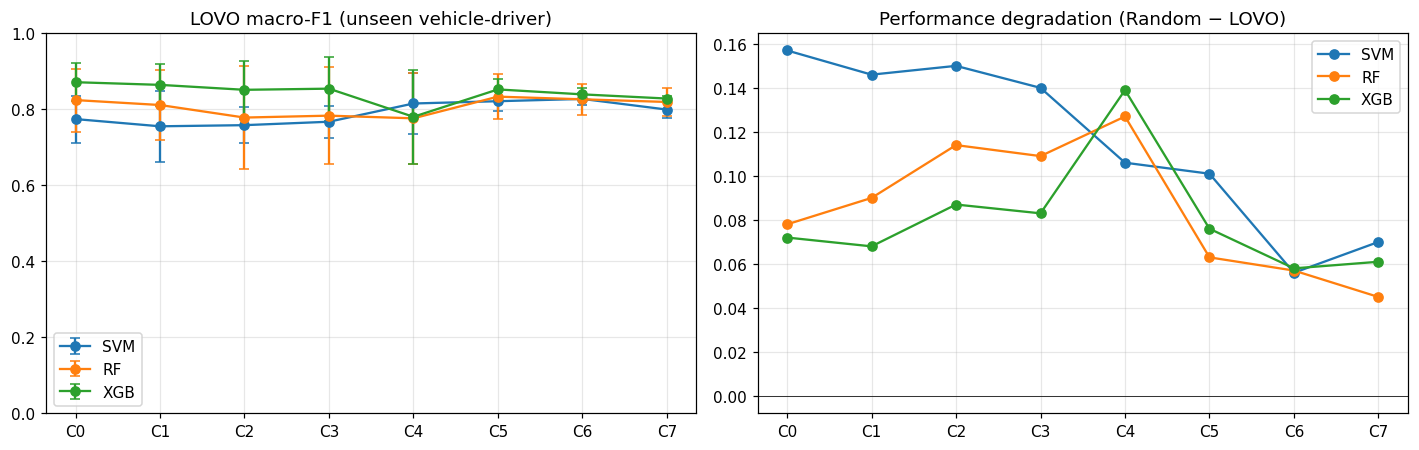

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
short = [c.split(' ')[0] for c in CONFIGS]
for m in MODELS:
    t = ABL.xs(m, level='model').reindex(list(CONFIGS))
    ax[0].errorbar(short, t['LOVO'], yerr=t['LOVO_std'], marker='o', capsize=3, label=m)
    ax[1].plot(short, t['Degradation'], marker='o', label=m)
ax[0].set_title('LOVO macro-F1 (unseen vehicle-driver)'); ax[0].set_ylim(0, 1)
ax[1].set_title('Performance degradation (Random − LOVO)'); ax[1].axhline(0, c='k', lw=.5)
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(c4.RESULTS_DIR, 'ablation.png'), dpi=150); plt.show()

In [8]:
# Per-class F1 under LOVO (mean over the three folds)
pc = abl[abl.split == 'LOVO'].groupby(['config', 'model'])[['f1_good', 'f1_regular', 'f1_bad', 'recall_bad']].mean()
display(pc.reindex(list(CONFIGS), level=0).round(3))

f1_good  f1_regular  f1_bad  recall_bad
config                       model                                         
C0 Baseline (raw)            RF       0.989       0.872   0.613       0.519
                             SVM      0.984       0.845   0.492       0.403
                             XGB      0.991       0.890   0.733       0.727
C1 + Noise handling          RF       0.988       0.863   0.581       0.499
                             SVM      0.984       0.816   0.466       0.467
                             XGB      0.992       0.882   0.717       0.731
C2 + Invariant repr.         RF       0.984       0.850   0.500       0.447
                             SVM      0.981       0.814   0.480       0.446
                             XGB      0.992       0.876   0.686       0.705
C3 + Manoeuvre filter        RF       0.986       0.852   0.512       0.457
                             SVM      0.982       0.820   0.497       0.453
                             XGB      0.991       0.880   0.690       0.700
C4 + Speed normalisation     RF       0.990       0.823   0.515       0.585
                             SVM      0.986       0.849   0.610       0.634
                             XGB      0.990       0.828   0.521       0.597
C5 + Per-trip normalisation  RF       0.990       0.863   0.646       0.619
                             SVM      0.983       0.831   0.649       0.662
                             XGB      0.990       0.868   0.700       0.706
C6 + Stable selection (FULL) RF       0.990       0.857   0.632       0.579
                             SVM      0.987       0.836   0.659       0.686
                             XGB      0.991       0.853   0.671       0.669
C7 Deployment (phone)        RF       0.990       0.851   0.616       0.567
                             SVM      0.975       0.808   0.612       0.620
                             XGB      0.990       0.839   0.654       0.676

## Interpretation guide
* A step **helps generalisation** if LOVO macro-F1 increases and/or degradation decreases.
* A step that increases Random but not LOVO performance learns context-specific patterns.
* If a step lowers LOVO performance, report it as a measured negative result and remove it from the final pipeline – this is still evidence for the design decision.
* Manoeuvre filtering keeps the test set fixed; it only changes the training data.